Name: Anna Bernardi

Date: 25/09/2025

# Introduction
The aim of this notebook is to provide a parametric model for testing the effectiveness of descriptive social norms on hotel customers. 
Seven experiments were conducted providing two groups of hotel guests with different messages to encourage the reusing of their towels: 
the control group received a message on the benefits of environmental protection, while the other (the social group) had a message stating that the majority of guests reused their towels.

More information about the data can be found in the following article:
Scheibehenne, B., Jamil, T., & Wagenmakers, E.-J. (2016). Bayesian Evidence Synthesis Can Reconcile Seemingly Inconsistent Results: The Case of Hotel Towel Reuse. Psychological Science, 27(7), 1043-1046. https://doi.org/10.1177/0956797616644081 (Original work published 2016)

# Code requirements 

In [9]:
import arviz as az
import bambi as bmb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data Wrangling 

The given data is converted into a pandas DataFrame for easier handling.

In [10]:
# read in data
data_file = "towelData.csv"
data = pd.read_csv(data_file, sep=';', encoding='latin1')
count = data.iloc[:, -1] # get the last column with numbers or yes/no

# count has the number of yes and no for control and social norm groups
control_yes = count[::4].to_numpy() # every 4th starting from 0 - control group + yes
control_no = count[2::4].to_numpy() # every 4th starting from 2 - control group + no
control_total = np.array([y + n for y, n in zip(control_yes, control_no)])

social_yes = count[1::4].to_numpy() # every 4th starting from 1 - social norm group + yes
social_no = count[3::4].to_numpy() # every 4th starting from 3 - social norm group + no
social_total = np.array([y + n for y, n in zip(social_yes, social_no)])

study = np.arange(1,len(control_yes)+1) # 7 diferent studies

control_data = pd.DataFrame({"reuse": control_yes, "total": control_total, "group": "control", "study": study})
social_data = pd.DataFrame({ "reuse": social_yes, "total": social_total, "group": "social", "study": study})

combined_data = pd.concat([control_data, social_data], ignore_index=True)

# Convert data types - important for bambi that they are correctly set 
# can give errors otherwise
combined_data['reuse'] = combined_data['reuse'].astype(int)
combined_data['total'] = combined_data['total'].astype(int)
combined_data['group'] = combined_data['group'].astype('category')
combined_data['study'] = combined_data['study'].astype('category')


combined_data['group_code'] = combined_data['group'].map({'control': 0, 'social': 1}).astype(int)

display(combined_data)

,reuse,total,group,study,group_code
0,74,211,control,1,0
1,103,277,control,2,0
2,77,135,control,3,0
3,82,187,control,4,0
4,21,25,control,5,0
5,123,147,control,6,0
6,28,30,control,7,0
7,98,222,social,1,1
8,587,1318,social,2,1
9,406,655,social,3,1


# Model

The data that was presented can be modelled by the Binomial distribution, letting the i-th observation be the number of times that the towel was reused among the $n_i$ total number across the $j$ (j=1,...,7) studies. 
The response variable is then:

$y_{ij} \sim Bin(n_{ij},p_{ij})$

The probability that the towel is reused, using the Binomial GLM, is:

$logit(p_{ij})=\beta _0 + \beta _1 x_{ij} + u_j$

Where: 
* $u_j$ is the random effect for study $j$ and we assume that $u_j \sim N(0,\tau ^2)$
* $x_{ij}$ equal to 0 for the control data (taken as the baseline) and 1 for the social data.
* $\beta _0$ the intercept
* $\beta _1$ the fixed effect due to the intervention.

In the code below:
* `p(reuse, total) ~ `  is the probability of the observed reuse $y_i$ over the total number $n_i$
* `1` is the intercept $\beta _0$
* `(1|study)` adds $u _j$
* `group_code` adds $\beta _1$

In [11]:
model_hierarchical = bmb.Model("p(reuse, total) ~ 1 + (1|study) + group_code", combined_data, family="binomial")
model_hierarchical

       Formula: p(reuse, total) ~ 1 + (1|study) + group_code
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 3.5355339059327378)
            group_code ~ Normal(mu: 0.0, sigma: 5.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 3.5355339059327378))

# Parameter estimation with Bayesian Inference 

## Priors
The priors assigned by default by Bambi are weakly informative, for our model they were:
* $\beta _0 \sim N(0,3.536)$
* $\beta _1 \sim N(0,5)$
* $u_j \sim HalfN(3.536)$
These priors were deemed too broad, as when trying to fit the hierarchical model we reported several divergences. 

We then swapped the default priors with tighter ones:
* $\beta _0 \sim N(0,2.5)$
* $\beta _1 \sim N(0,1)$
* $u_j \sim HalfN(1)$

With these priors, the model fit stabilized (no divergences).




In [12]:
priors = {
    "Intercept": bmb.Prior("Normal", mu=0, sigma=2.5),
    "group_code": bmb.Prior("Normal", mu=0, sigma=1.0),
    "sd|study": bmb.Prior("HalfNormal", sigma=1.0),
}
model_hierarchical = bmb.Model("p(reuse, total) ~ 1 + (1|study) + group_code", combined_data, family="binomial", priors=priors)
model_hierarchical


       Formula: p(reuse, total) ~ 1 + (1|study) + group_code
        Family: binomial
          Link: p = logit
  Observations: 14
        Priors: 
    target = p
        Common-level effects
            Intercept ~ Normal(mu: 0.0, sigma: 2.5)
            group_code ~ Normal(mu: 0.0, sigma: 1.0)
        
        Group-level effects
            1|study ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 2.5))

In [13]:
fit_result = model_hierarchical.fit(draws=2000,tune=1000,target_accept=0.95)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, group_code, 1|study_sigma, 1|study_offset]


c:\Users\annab\AppData\Local\Programs\Python\Python313\Lib\site-packages\rich\live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1318 seconds.


In [14]:
summary = az.summary(fit_result, hdi_prob=0.9)  #with 90% probability interval
print(summary)

                mean     sd  hdi_5%  hdi_95%  mcse_mean  mcse_sd  ess_bulk  \
Intercept      0.437  0.450  -0.264    1.158      0.011    0.011    1766.0   
group_code     0.210  0.077   0.084    0.336      0.001    0.001    4445.0   
1|study_sigma  1.120  0.418   0.530    1.673      0.011    0.010    1470.0   
1|study[1]    -0.954  0.457  -1.668   -0.228      0.011    0.011    1803.0   
1|study[2]    -0.881  0.450  -1.614   -0.194      0.011    0.011    1757.0   
1|study[3]    -0.155  0.452  -0.849    0.576      0.011    0.011    1746.0   
1|study[4]    -0.650  0.451  -1.373    0.046      0.011    0.011    1786.0   
1|study[5]     1.117  0.556   0.204    1.966      0.011    0.010    2389.0   
1|study[6]     0.928  0.453   0.172    1.619      0.011    0.011    1777.0   
1|study[7]     0.737  0.474  -0.010    1.493      0.011    0.011    1929.0   

               ess_tail  r_hat  
Intercept        2257.0    1.0  
group_code       3946.0    1.0  
1|study_sigma    2352.0    1.0  
1|study[1

# Effectiveness of the intervention (posterior inference)
### Hypothesis

We will focus on the intervention effect parameter $\beta _1$

- $H_0: \beta _1 = 0$  (intervention has no effect)
- $H_1: \beta _1 \neq 0$ (intervention has an effect)

To be tested at a significance level $\alpha = 10 \% $ 

### Posterior summary
We summarize the intervention effect ($\beta _1$) using the 90% Highest Density Interval (HDI) which is the range of values containing 90% of the posterior probability. 

In [15]:
posterior_group = fit_result.posterior["group_code"].values.flatten() #extracting a 1D array of posterior draws for beta1

#posterior summaries
posterior_mean = posterior_group.mean()
hdi = az.hdi(posterior_group, hdi_prob=0.9)
p_pos = (posterior_group > 0).mean()


print(f"Posterior mean (β1): {posterior_mean:.3f}")
print(f"90% HDI: [{hdi[0]:.3f}, {hdi[1]:.3f}]")


Posterior mean (β1): 0.210
90% HDI: [0.084, 0.336]


Since 0 is not contained in the 90% HDI we posses strong evidence that descriptive social norms had an effect on the hotel guests.

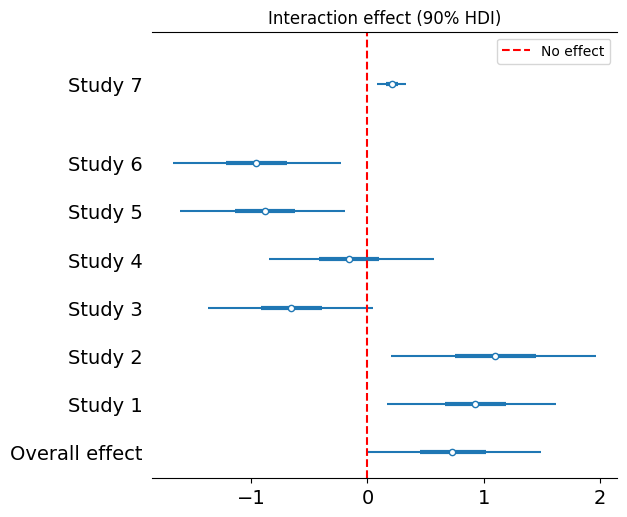

In [22]:
#intervention effect
ax = az.plot_forest(fit_result, var_names=["group_code", "1|study"], combined=True, hdi_prob=0.9)
param_labels = ["Overall effect"] + [f"Study {i}" for i in range(1, 8)]

ax[0].set_yticklabels(param_labels)

plt.axvline(0, color='red', linestyle='--', label='No effect')
plt.title("Interaction effect (90% HDI)")
plt.legend()
plt.show()

The forest plot shows both the overall effect and the study-level effects of the social norm messege on towel reuse.

* The Overall effect represents the overall pooled effect across all studies. Its 90% HDI does not cross zero, suggesting that the intervention had an effect of towel reuse on average
* Each study line shows the estimated study-level effect with its 90% HDI.  
* If a study’s HDI crosses the red "no effect" line ($\beta _1= 0$) (e.g. Study 4), the data from that study alone is inconclusive, thus the $H_0$ hypothesis cannot be rejected 

Overall, the forest plot illustrates that while some individual studies are uncertain, the pooled intervention effect is positive.
